In [3]:
"""

Model (letter, Sec. II)
    y_{n,k} = sgn(x_k + sigma * xi_{n,k} - theta_m),   xi_{n,k} ~ N(0, 1) i.i.d.,
    N elements in M groups (group m: N_m elements, threshold theta_m),
    group averages s_{m,k}, decoder  xhat_k = w^T s_k.

Adaptation (letter, Sec. III)
    weights : RLS, eq. (8)  (regularization R_w, prior P_0 = P0_w * I, w_0)
    scale   : scalar EKF, eq. (9)  (Q_sigma, R_sigma, P0_sigma)
              with the measured innovation  eps_k = x_k - s_k^T w_{k-1}
              or the mean-response innovation x_k - w_{k-1}^T hbar(x_k, sigma_{k-1}).

"""
from __future__ import annotations

from dataclasses import dataclass, replace
from typing import Optional, Sequence, Tuple

import numpy as np
from scipy import integrate, optimize, special

from dataclasses import dataclass

SQRT2 = np.sqrt(2.0)
SQRT2PI = np.sqrt(2.0 * np.pi)


# ---------------------------------------------------------------------------
# Gaussian PDF, 平均响应，以及其导数
# ---------------------------------------------------------------------------
def gauss_pdf(u):
    return np.exp(-0.5 * np.asarray(u, dtype=float) ** 2) / SQRT2PI
def hbar(x, sigma, theta):
    """Smoothed response E[sgn(x + sigma*xi - theta) | x] = 2 Phi((x-theta)/sigma) - 1
                        =erf((x - theta) / (sigma * SQRT2))
    """
    return special.erf((x - theta) / (sigma * SQRT2))

def hbar_prime(x, sigma, theta):
    """Scale derivative of the smoothed response, letter eq. (3), Gaussian dither."""
    return -2.0 * (x - theta) / sigma ** 2 * gauss_pdf((x - theta) / sigma)

# M=1 高斯信号高斯噪声理论结果计算--------------------------------------------------------------

def p_single(sigma, sx=1.0):
    """p(sigma) = E[x hbar] = sqrt(2/pi) sx^2 / sqrt(sx^2 + sigma^2)."""
    return np.sqrt(2.0 / np.pi) * sx ** 2 / np.sqrt(sx ** 2 + np.asarray(sigma, float) ** 2)

def psi_single(sigma, sx=1.0):
    """psi(sigma) = E[hbar^2] = (2/pi) arcsin(sx^2 / (sx^2 + sigma^2))."""
    return (2.0 / np.pi) * np.arcsin(sx ** 2 / (sx ** 2 + np.asarray(sigma, float) ** 2))

def dp_single(sigma, sx=1.0):
    sigma = np.asarray(sigma, float)
    return -np.sqrt(2.0 / np.pi) * sx ** 2 * sigma / (sx ** 2 + sigma ** 2) ** 1.5

def dpsi_single(sigma, sx=1.0):
    sigma = np.asarray(sigma, float)
    return -(4.0 / np.pi) * sx ** 2 / ((sx ** 2 + sigma ** 2) * np.sqrt(sigma ** 2 + 2.0 * sx ** 2))

def zeta_min_single(sigma, N, sx=1.0):
    """Letter eq. (5): E[x^2] - N p^2 / (1 + (N-1) psi)."""
    p, psi = p_single(sigma, sx), psi_single(sigma, sx)
    return sx ** 2 - N * p ** 2 / (1.0 + (N - 1) * psi)

def w_opt_single(sigma, N, sx=1.0):
    """Wiener coefficient on the average s_k: w^o = N p / (1 + (N-1) psi)."""
    return N * p_single(sigma, sx) / (1.0 + (N - 1) * psi_single(sigma, sx))

def sigma_opt_single(N, sx=1.0):
    """MSE-optimal scale sigma^o of eq. (5); sigma^o = 0 for N = 1 (no noise benefit)."""
    if N == 1:
        return 0.0
    res = optimize.minimize_scalar(lambda s: zeta_min_single(s, N, sx), bounds=(1e-6, 10.0 * sx),
                                   method="bounded", options={"xatol": 1e-10})
    return float(res.x)

##EKF稳态收敛值 sigma^\ast
def sigma_meanfield_single(N, sx=1.0):
    """Mean-field equilibrium sigma^dagger of the scale update (letter, Proposition 1, eq. (12)):
    p'(sigma) [1 + (N-1) psi(sigma)] = (N/2) p(sigma) psi'(sigma)."""
    f = lambda s: dp_single(s, sx) * (1.0 + (N - 1) * psi_single(s, sx)) - 0.5 * N * p_single(s, sx) * dpsi_single(s, sx)
    return float(optimize.brentq(f, 1e-3 * sx, 50.0 * sx, xtol=1e-13))

# ---------------------------------------------------------------------------
# M groups, input x ~ N(0, sx^2), Gaussian dither: Wiener solution and mean field
# ---------------------------------------------------------------------------
def _expect(fun, sx=1.0, points=None):
    """E[fun(x)] for x ~ N(0, sx^2) by adaptive quadrature."""
    lo, hi = -12.0 * sx, 12.0 * sx
    pts = None if points is None else [p for p in points if lo < p < hi]
    val, _ = integrate.quad(lambda x: fun(x) * gauss_pdf(x / sx) / sx, lo, hi,
                            points=pts, limit=500, epsabs=1e-13, epsrel=1e-11)
    return val


def grouped_moments(sigma, thetas, Ns, sx=1.0):
    """p_m = E[x hbar_m] (closed form), R_mm = E[hbar_m^2] + E[1 - hbar_m^2]/N_m,
    R_mn = E[hbar_m hbar_n] (letter, Sec. II)."""
    th = np.asarray(thetas, float)
    Nm = np.asarray(Ns, float)
    tau = np.sqrt(sx ** 2 + sigma ** 2)
    p = 2.0 * sx ** 2 * gauss_pdf(th / tau) / tau
    M = th.size
    R = np.empty((M, M))
    for i in range(M):
        for j in range(i, M):
            R[i, j] = R[j, i] = _expect(lambda x, a=th[i], b=th[j]: hbar(x, sigma, a) * hbar(x, sigma, b),
                                        sx, list(th))
    R[np.diag_indices(M)] += (1.0 - np.diag(R)) / Nm
    return p, R


def zeta_min_grouped(sigma, thetas, Ns, sx=1.0):
    """Minimum MSE over the group weights and the Wiener weights: (zeta_min, w_opt)."""
    p, R = grouped_moments(sigma, thetas, Ns, sx)
    w = np.linalg.solve(R, p)
    return float(sx ** 2 - p @ w), w


def sigma_opt_grouped(thetas, Ns, sx=1.0, bounds=(0.02, 5.0)):
    res = optimize.minimize_scalar(lambda s: zeta_min_grouped(s, thetas, Ns, sx)[0],
                                   bounds=(bounds[0] * sx, bounds[1] * sx), method="bounded",
                                   options={"xatol": 1e-8})
    return float(res.x)


def drift_grouped(sigma, thetas, Ns, sx=1.0):
    """Mean field of the scale update, letter eq. (11), evaluated at w = w^o(sigma):
    b = E[(w^T hbar') (x - w^T hbar)]."""
    th = np.asarray(thetas, float)
    _, w = zeta_min_grouped(sigma, th, Ns, sx)

    def f(x):
        return (w @ hbar_prime(x, sigma, th)) * (x - w @ hbar(x, sigma, th))

    return _expect(f, sx, list(th))


def sigma_meanfield_grouped(thetas, Ns, sx=1.0, grid=None):
    """Equilibrium sigma^dagger of the scale update for M groups (root of the drift)."""
    grid = np.linspace(0.05, 4.0, 80) * sx if grid is None else np.asarray(grid)
    vals = [drift_grouped(s, thetas, Ns, sx) for s in grid]
    for a, b, fa, fb in zip(grid[:-1], grid[1:], vals[:-1], vals[1:]):
        if fa > 0 >= fb:   # stable root: drift changes from upward to downward
            return float(optimize.brentq(drift_grouped, a, b, args=(thetas, Ns, sx), xtol=1e-10))
    raise RuntimeError("no stable root of the mean-field drift found on the grid")


# ---------------------------------------------------------------------------
# Configurations and the vectorized adaptive simulation
# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class ArrayConfig:
    thetas: Tuple[float, ...] = (0.0,)
    Ns: Tuple[int, ...] = (31,)

    @property
    def N(self) -> int:
        return int(sum(self.Ns))

    @property
    def M(self) -> int:
        return len(self.Ns)

    def slices(self):
        out, a = [], 0
        for n in self.Ns:
            out.append(slice(a, a + n))
            a += n
        return out


@dataclass(frozen=True)
class AdaptConfig:
    # RLS weights, letter eq. (8)
    R_w: float = 0.1
    P0_w: float = 10.0             # P_0 = P0_w * I
    w0: float = 1.0                # initial weight of every group
    # scale update
    scale_rule: str = "ekf"        # 'ekf' (eq. (10)), 'fixed', or 'grad' (gradient control G)
    Q_sigma: float = 1e-3
    R_sigma: float = 1.0
    P0_sigma: float = 2.0
    innovation: str = "measured"   # 'measured' eps_k, or 'mean' (mean-response innovation)
    jacobian_weights: str = "updated"  # 'updated' (w_k, as in the notebooks) or 'previous' (w_{k-1})
    clip: Optional[float] = 0.2    # max |sigma_k - sigma_{k-1}| (None: no clipping)
    bounds: Optional[Tuple[float, float]] = (0.03, 5.0)  # sigma_k kept in [lo, hi] (None: no bounds)
    mu: float = 0.0                # step size of the gradient control (log-sigma)
    grad_log_clip: Optional[float] = 1.0  # guard on |log-step| of the gradient control


In [4]:
# Settings used in the letter (Sec. V): measured innovation, H_k at the updated
# weights, safeguards as stated in the letter.
SINGLE = ArrayConfig(thetas=(0.0,), Ns=(31,))
TWO_GROUPS = ArrayConfig(thetas=(-0.5, 0.5), Ns=(15, 16))
CFG_SINGLE = AdaptConfig(w0=1.0, clip=0.2, bounds=(0.03, 5.0))
CFG_TWO_GROUPS = AdaptConfig(w0=0.5, clip=0.5, bounds=(0.03, 5.0))
SIGMA0_LIST = (0.1, 0.5, 1.5, 4.0)
N_TRIALS = 20
N_SAMPLES = 3000
LATE_START = 1500          # late window = samples with 0-based index >= 1500
MASTER_SEED = 20261019

In [5]:
def run_adaptive(x, xi, arr: ArrayConfig, cfg: AdaptConfig, sigma0, stream_idx=None,
                 sigma_fixed=None, mu=None, record=True):
    """Simulate the adaptive SSR array for a batch of B runs in parallel.

    x          : (S, K) input samples of S streams (a 1-D array is one stream).
    xi         : (S, K, N) standardized dither of the same streams, N = sum(Ns).
    stream_idx : (B,) stream used by each batch row (default: one row per stream).
    sigma0     : scalar or (B,) initial scale (ignored for 'fixed').
    sigma_fixed: scalar or (B,) scale for cfg.scale_rule == 'fixed'.
    mu         : scalar or (B,) step size for cfg.scale_rule == 'grad' (default cfg.mu).

    At time k the array operates with sigma_{k-1}; the prediction uses w_{k-1};
    then RLS updates w and the scale rule updates sigma (letter, Sec. III).
    Returns a dict with trajectories (if record) and the final state.
    """
    x = np.atleast_2d(np.asarray(x, float))
    xi = np.asarray(xi)                      # float32 or float64; not copied
    if xi.ndim == 2:
        xi = xi[None]
    S, K = x.shape
    if stream_idx is None:
        stream_idx = np.arange(S)
    stream_idx = np.asarray(stream_idx, int)
    B, M, N = stream_idx.size, arr.M, arr.N
    th = np.asarray(arr.thetas, float)
    Nm = np.asarray(arr.Ns, float)
    sl = arr.slices()
    if xi.shape[-1] != N:
        raise ValueError("dither has %d columns, array has %d elements" % (xi.shape[-1], N))

    w = np.full((B, M), float(cfg.w0))
    P = np.broadcast_to(np.eye(M) * cfg.P0_w, (B, M, M)).copy()
    if cfg.scale_rule == "fixed":
        sigma = np.broadcast_to(np.asarray(sigma_fixed, float), (B,)).copy()
    else:
        sigma = np.broadcast_to(np.asarray(sigma0, float), (B,)).copy()
    Psig = np.full(B, float(cfg.P0_sigma))
    mu_b = np.broadcast_to(np.asarray(cfg.mu if mu is None else mu, float), (B,))
    failed = np.zeros(B, bool)

    if record:
        sig_tr = np.empty((B, K)); w_tr = np.empty((B, K, M)); H_tr = np.zeros((B, K))
        xhat_tr = np.empty((B, K)); err2_tr = np.empty((B, K))

    for k in range(K):
        xk = x[stream_idx, k]
        xik = xi[stream_idx, k, :]
        s = np.empty((B, M))
        for m in range(M):
            s[:, m] = np.sign(xk[:, None] + sigma[:, None] * xik[:, sl[m]] - th[m]).mean(axis=1)
        xhat = np.einsum("bm,bm->b", w, s)
        eps = xk - xhat
        if record:
            sig_tr[:, k] = sigma; xhat_tr[:, k] = xhat; err2_tr[:, k] = eps ** 2

        # --- RLS weights, eq. (8)
        Ps = np.einsum("bij,bj->bi", P, s)
        den = np.einsum("bi,bi->b", s, Ps) + cfg.R_w
        g = Ps / den[:, None]
        w_prev = w
        w = w + g * eps[:, None]
        P = P - np.einsum("bi,bj->bij", g, Ps)

        # --- scale update
        if cfg.scale_rule == "fixed":
            if record:
                w_tr[:, k] = w
            continue
        ss = np.maximum(sigma, 1e-2)                       # as in the notebooks
        dx = xk[:, None] - th[None, :]
        hp = -2.0 * dx / ss[:, None] ** 2 * gauss_pdf(dx / ss[:, None])     # hbar'
        if cfg.scale_rule == "ekf":
            wj = w if cfg.jacobian_weights == "updated" else w_prev
            H = np.einsum("bm,bm->b", wj, hp)
            if cfg.innovation == "measured":
                e = eps
            else:
                e = xk - np.einsum("bm,bm->b", w_prev, special.erf(dx / (ss[:, None] * SQRT2)))
            Kg = Psig * H / (H * H * Psig + cfg.R_sigma)
            step = Kg * e
            if cfg.clip is not None:
                step = np.clip(step, -cfg.clip, cfg.clip)
            sigma_new = sigma + step
            Psig = (1.0 - Kg * H) * Psig + cfg.Q_sigma
            if record:
                H_tr[:, k] = H
        elif cfg.scale_rule == "grad":
            hb = special.erf(dx / (ss[:, None] * SQRT2))
            resid = xk - np.einsum("bm,bm->b", w_prev, hb)
            # d/dsigma of the conditional finite-array loss (letter eq. (4), M groups)
            dloss = (-2.0 * resid * np.einsum("bm,bm->b", w_prev, hp)
                     - 2.0 * np.einsum("bm,bm->b", w_prev ** 2 / Nm[None, :], hb * hp))
            logstep = -mu_b * sigma * dloss
            if cfg.grad_log_clip is not None:
                logstep = np.clip(logstep, -cfg.grad_log_clip, cfg.grad_log_clip)
            sigma_new = sigma * np.exp(logstep)
        else:
            raise ValueError(cfg.scale_rule)
        if cfg.bounds is not None:
            sigma_new = np.clip(sigma_new, cfg.bounds[0], cfg.bounds[1])
        bad = ~np.isfinite(sigma_new) | (sigma_new <= 0)
        if bad.any():                                      # unprojected recursion left its domain
            failed |= bad
            sigma_new = np.where(bad, np.where(np.isfinite(sigma), np.abs(sigma), 1.0) + 1e-6, sigma_new)
        sigma = sigma_new
        if record:
            w_tr[:, k] = w

    out = {"w": w, "sigma": sigma, "P": P, "P_sigma": Psig, "failed": failed}
    if record:
        out.update(sigma_traj=sig_tr, w_traj=w_tr, H_traj=H_tr, xhat=xhat_tr, err2=err2_tr)
    return out


def predict_frozen(x, xi, arr: ArrayConfig, w, sigma):
    """Reconstruction with frozen weights w (B, M) and scale sigma (B,).
    x: (B, K), xi: (B, K, N). Returns xhat (B, K)."""
    x = np.atleast_2d(np.asarray(x, float))
    th = np.asarray(arr.thetas, float)
    sigma = np.asarray(sigma, float).reshape(-1, 1, 1)
    xhat = np.zeros_like(x)
    for m, sl in enumerate(arr.slices()):
        sm = np.sign(x[..., None] + sigma * xi[..., sl] - th[m]).mean(axis=-1)
        xhat += np.asarray(w)[:, m][:, None] * sm
    return xhat


def run_convergence_study(arr: ArrayConfig, cfg: AdaptConfig, sigma0_list=SIGMA0_LIST,
                          n_trials=N_TRIALS, K=N_SAMPLES, seed=MASTER_SEED, tag=0):
    """Stationary study of Fig. 2 / Table I: for each trial one input stream and one dither
    stream, shared by all initial scales (paired across sigma0).
    Returns {sigma0: dict of arrays with shape (n_trials, ...)}."""
    ss = np.random.SeedSequence([seed, tag])
    rngs = [np.random.default_rng(c) for c in ss.spawn(n_trials)]
    x = np.stack([r.standard_normal(K) for r in rngs])
    xi = np.stack([r.standard_normal((K, arr.N)) for r in rngs])
    n0 = len(sigma0_list)
    stream_idx = np.tile(np.arange(n_trials), n0)
    sigma0 = np.repeat(np.asarray(sigma0_list, float), n_trials)
    out = run_adaptive(x, xi, arr, cfg, sigma0, stream_idx=stream_idx)
    res = {}
    for i, s0 in enumerate(sigma0_list):
        rows = slice(i * n_trials, (i + 1) * n_trials)
        res[s0] = {key: out[key][rows] for key in
                   ("sigma_traj", "w_traj", "H_traj", "xhat", "err2", "failed")}
        res[s0]["x"] = x
    return res


# ---------------------------------------------------------------------------
# Metrics
# ---------------------------------------------------------------------------
def moving_average(e2, window, partial=True):
    """Causal moving average along the last axis. For the first window-1 samples the
    mean over the available samples is used (partial=True) or NaN (partial=False)."""
    e2 = np.asarray(e2, float)
    K = e2.shape[-1]
    c = np.cumsum(e2, axis=-1)
    out = np.empty_like(c)
    lag = np.concatenate([np.zeros(c.shape[:-1] + (1,)), c[..., :K - window]], axis=-1)
    out[..., window - 1:] = (c[..., window - 1:] - lag) / window
    if partial:
        out[..., :window - 1] = c[..., :window - 1] / np.arange(1, window)
    else:
        out[..., :window - 1] = np.nan
    return out


def first_passage(e2, threshold, window=50):
    """First time k >= window (1-based) at which the causal window-sample moving
    average of e2 falls below threshold (letter, Sec. V-A). NaN if never."""
    ma = moving_average(e2, window, partial=False)
    e2 = np.atleast_2d(e2)
    ma = np.atleast_2d(ma)
    T = np.full(e2.shape[0], np.nan)
    for i in range(e2.shape[0]):
        idx = np.flatnonzero(ma[i] < threshold)
        if idx.size:
            T[i] = idx[0] + 1
    return T


# ---------------------------------------------------------------------------
# Speech test signal (letter, Sec. V-D; identical to the original notebook)
# ---------------------------------------------------------------------------
def synth_vowel_a(fs=8000, duration=3.0, F0=120.0, harmonics=25,
                  formants=((800.0, 80.0), (1200.0, 100.0), (2500.0, 150.0)), peak=0.9):
    """Synthesized vowel /a/: 25 harmonics (amplitude 1/k) of F0 through three
    second-order formant resonators, normalized to a peak of 0.9."""
    from scipy.signal import lfilter
    t = np.arange(0.0, duration, 1.0 / fs)
    src = np.zeros_like(t)
    for k in range(1, harmonics + 1):
        src += np.sin(2.0 * np.pi * k * F0 * t) / k
    y = src
    for fc, bw in formants:
        r = np.exp(-np.pi * bw / fs)
        th = 2.0 * np.pi * fc / fs
        y = lfilter([1.0 - r], [1.0, -2.0 * r * np.cos(th), r * r], y)
    y = y / np.max(np.abs(y)) * peak
    return t, y


# ---------------------------------------------------------------------------
# Plot helpers (EPS-safe: shading by lightened colors instead of transparency)
# ---------------------------------------------------------------------------
def set_plot_style():
    import matplotlib as mpl
    mpl.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 15, "axes.labelsize": 15, "legend.fontsize": 13,
        "axes.unicode_minus": False,
        "ps.fonttype": 42, "pdf.fonttype": 42,
    })


def lighten(color, amount=0.3):
    """Mix a color with white; amount = 0 gives white, 1 the original color."""
    import colorsys
    import matplotlib.colors as mc
    h, l, s = colorsys.rgb_to_hls(*mc.to_rgb(color))
    return colorsys.hls_to_rgb(h, 1.0 - amount * (1.0 - l), s)


def save_figure(fig, stem, out_dir="."):
    """Save stem.eps (used by the letter), stem.pdf and stem.png."""
    import os
    os.makedirs(out_dir, exist_ok=True)
    for ext, kw in (("eps", {}), ("pdf", {}), ("png", {"dpi": 300})):
        fig.savefig(os.path.join(out_dir, f"{stem}.{ext}"), bbox_inches="tight", **kw)


In [6]:
import numpy as np
from scipy import integrate, optimize, special
# ==================== Random seed ====================
SEED = 2026

np.random.seed(SEED)
import random
import torch

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# ---- closed forms (x ~ N(0,1), Gaussian dither) ---------------------------
def p(sigma):
    return np.sqrt(2.0 / np.pi) / np.sqrt(1.0 + sigma ** 2)


def psi(sigma):
    return (2.0 / np.pi) * np.arcsin(1.0 / (1.0 + sigma ** 2))


def zeta_min(sigma, N):
    return 1.0 - N * p(sigma) ** 2 / (1.0 + (N - 1) * psi(sigma))


def w_opt(sigma, N):
    return N * p(sigma) / (1.0 + (N - 1) * psi(sigma))


# ---- direct numerical integration (independent check of the closed forms) --
def phi(x):
    return np.exp(-0.5 * x * x) / np.sqrt(2.0 * np.pi)


def hbar(x, sigma):
    return special.erf(x / (sigma * np.sqrt(2.0)))


def p_numeric(sigma):
    return integrate.quad(lambda x: x * hbar(x, sigma) * phi(x), -12, 12, points=[0.0], limit=400)[0]


def psi_numeric(sigma):
    return integrate.quad(lambda x: hbar(x, sigma) ** 2 * phi(x), -12, 12, points=[0.0], limit=400)[0]


print("1) Closed forms versus numerical integration")
print("   sigma      p(closed)     p(quad)       psi(closed)   psi(quad)")
for s in (0.05, 0.25, 0.7, 1.0, 2.0):
    print(f"   {s:5.2f}   {p(s):.10f}  {p_numeric(s):.10f}  {psi(s):.10f}  {psi_numeric(s):.10f}")
    assert abs(p(s) - p_numeric(s)) < 1e-9 and abs(psi(s) - psi_numeric(s)) < 1e-9

print("\n2) MSE-optimal noise scale for N >= 2 (letter eq. (5))")
print("   N    sigma^o    zeta^min(sigma^o)   w^o (coefficient on the average s_k)")
stated = {2: (0.249, 0.327), 10: (0.693, 0.181), 31: (1.007, 0.103), 61: (1.210, 0.071)}
results = {}

for N in (2, 10, 31, 61):
    res = optimize.minimize_scalar(
        lambda s: zeta_min(s, N),
        bounds=(1e-6, 10.0),
        method="bounded",
        options={"xatol": 1e-12}
    )
    s_o, z_o = float(res.x), float(res.fun)
    results[N] = (s_o, z_o, w_opt(s_o, N))
    print(f"   {N:2d}   {s_o:.4f}     {z_o:.4f}              {w_opt(s_o, N):.4f}")

    # Agreement with the values printed in the letter (3 decimals)
    assert round(s_o, 3) == stated[N][0], (N, s_o)
    assert round(z_o, 3) == stated[N][1], (N, z_o)

assert round(results[31][2], 3) == 1.596

print("\n3) N = 1: no noise benefit")
grid = np.linspace(1e-4, 5.0, 2001)
z1 = zeta_min(grid, 1)

print(f"   zeta^min(0+) = {zeta_min(1e-12, 1):.6f},  1 - 2/pi = {1 - 2 / np.pi:.6f}")
print(f"   zeta^min increasing on (0, 5]: {bool(np.all(np.diff(z1) > 0))}")

print("\n4) Small-noise slope of Theorem 1, eq. (6)")
fx0, C_xi, Eabs = 1.0 / np.sqrt(2.0 * np.pi), 1.0 / np.sqrt(np.pi), np.sqrt(2.0 / np.pi)

C_num = integrate.quad(
    lambda z: special.ndtr(z) * (1.0 - special.ndtr(z)),
    -40, 40
)[0]

print(f"   C_xi: closed form {C_xi:.10f}, numerical {C_num:.10f}")

for N in (2, 31):
    slope = -(4.0 * (N - 1) / N) * fx0 * C_xi * Eabs ** 2
    h = 1e-5
    fd = (zeta_min(h, N) - zeta_min(1e-12, N)) / h
    print(f"   N = {N:2d}: theory {slope:.6f}, finite difference {fd:.6f}")

print("\nRounded as in the letter:")
print("   sigma^o      = " + ", ".join(f"{results[N][0]:.3f}" for N in (2, 10, 31, 61)))
print("   zeta^min     = " + ", ".join(f"{results[N][1]:.3f}" for N in (2, 10, 31, 61)))
print(f"   N = 1:  1 - 2/pi = {1 - 2 / np.pi:.3f};   w^o(N = 31) = {results[31][2]:.3f}")

1) Closed forms versus numerical integration
   sigma      p(closed)     p(quad)       psi(closed)   psi(quad)
    0.05   0.7968890713  0.7968890713  0.9550310002  0.9550310002
    0.25   0.7740617226  0.7740617226  0.7805564134  0.7805564134
    0.70   0.6536525011  0.6536525011  0.4683909361  0.4683909361
    1.00   0.5641895835  0.5641895835  0.3333333333  0.3333333333
    2.00   0.3568248232  0.3568248232  0.1281884337  0.1281884337

2) MSE-optimal noise scale for N >= 2 (letter eq. (5))
   N    sigma^o    zeta^min(sigma^o)   w^o (coefficient on the average s_k)
    2   0.2489     0.3270              0.8692
   10   0.6930     0.1808              1.2492
   31   1.0073     0.1029              1.5958
   61   1.2097     0.0709              1.8277

3) N = 1: no noise benefit
   zeta^min(0+) = 0.363380,  1 - 2/pi = 0.363380
   zeta^min increasing on (0, 5]: True

4) Small-noise slope of Theorem 1, eq. (6)
   C_xi: closed form 0.5641895835, numerical 0.5641895835
   N =  2: theory -0.2865

sigma^o = 1.0073, w^o = 1.5958, zeta^min = 0.1029
sigma^dagger = 1.1164, w^dagger = 1.6820
saved Fig7.eps/.pdf/.png in D:/


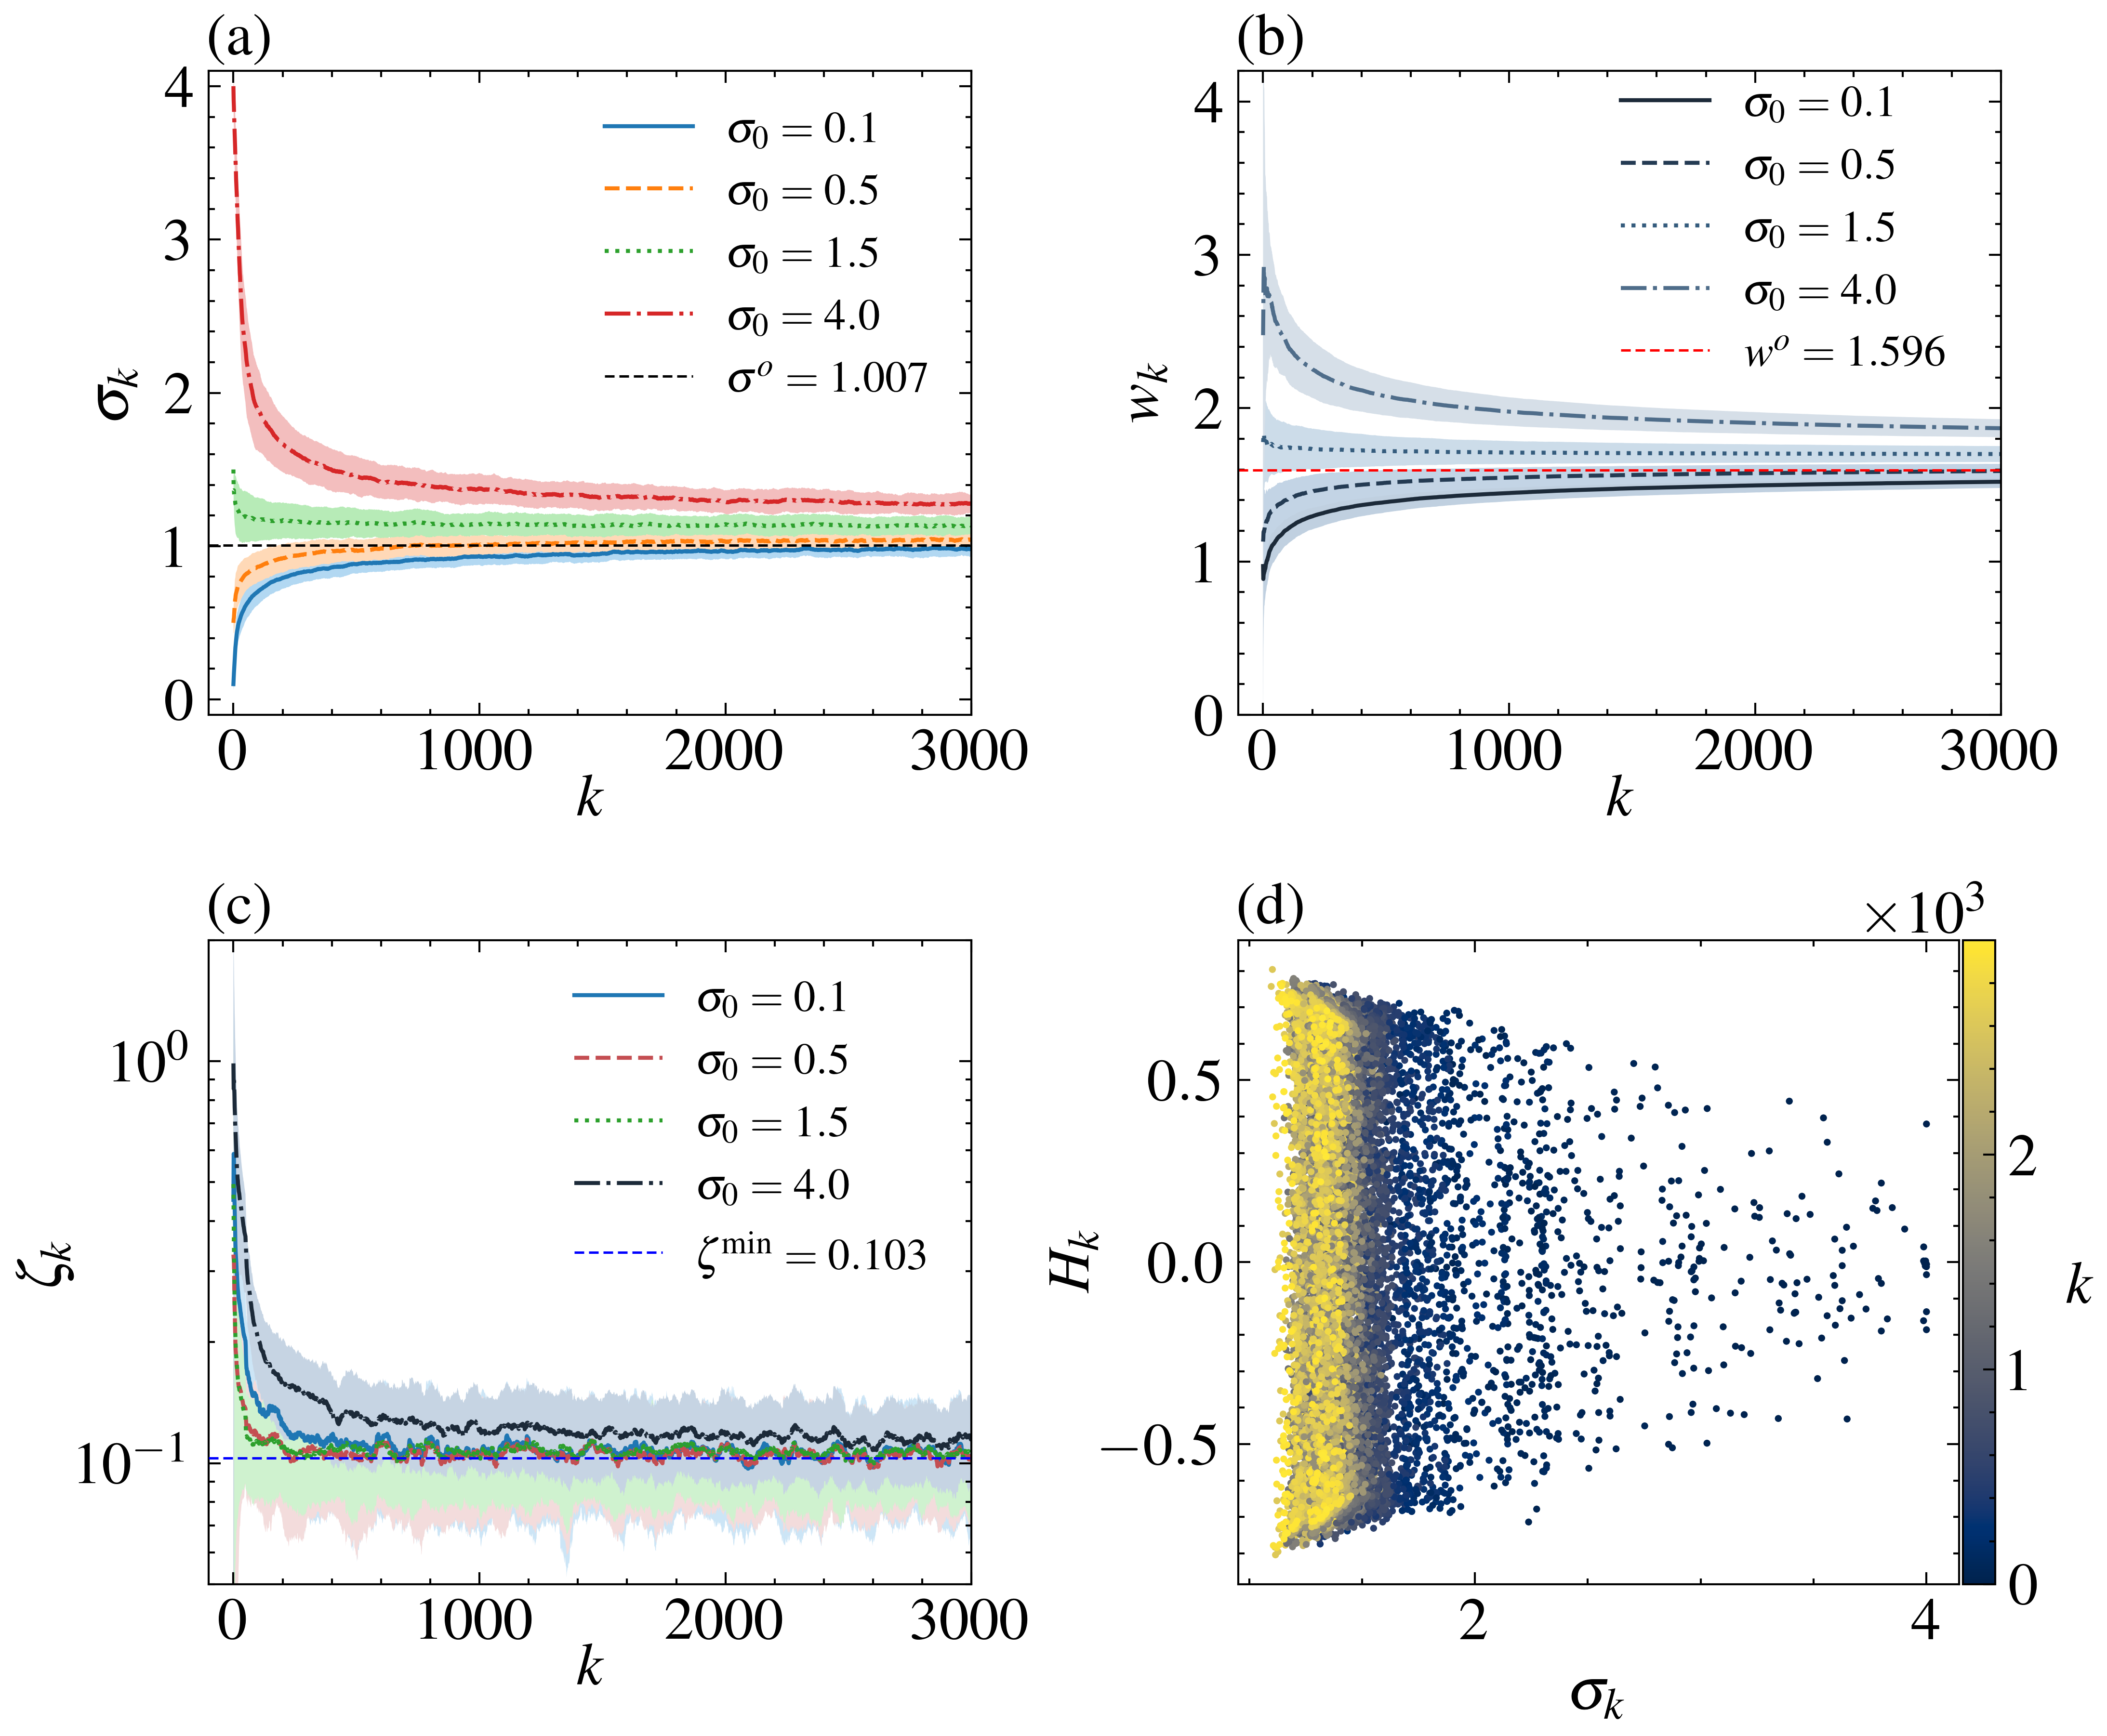

In [7]:
%matplotlib inline

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import ssr_common as sc
# -------------------- 双子图出版图 (Fig. 2) --------------------
try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "ieee"])
    matplotlib.rcParams["font.serif"] = ["Times New Roman"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except Exception:
    pass  # 未装 scienceplots 时退化为默认样式

# ============================================================
# Parameters (Jupyter Notebook)
# ============================================================
OUT_DIR = "D:/"
STEM = "Fig7"
TRIALS = sc.N_TRIALS
SAMPLES = sc.N_SAMPLES
NO_MEANFIELD = True


# ============================================================
# Theoretical reference values
# ============================================================
N = sc.SINGLE.N

s_opt = sc.sigma_opt_single(N)
w_opt = sc.w_opt_single(s_opt, N)
z_opt = sc.zeta_min_single(s_opt, N)

s_dag = sc.sigma_meanfield_single(N)
w_dag = sc.w_opt_single(s_dag, N)

print(f"sigma^o = {s_opt:.4f}, w^o = {w_opt:.4f}, zeta^min = {z_opt:.4f}")
print(f"sigma^dagger = {s_dag:.4f}, w^dagger = {w_dag:.4f}")


# ============================================================
# Run convergence experiments
# ============================================================
res = sc.run_convergence_study(
    sc.SINGLE,
    sc.CFG_SINGLE,
    sc.SIGMA0_LIST,
    n_trials=TRIALS,
    K=SAMPLES
)

for s0 in sc.SIGMA0_LIST:
    if res[s0]["failed"].any():
        print(
            f"warning: {res[s0]['failed'].sum()} "
            f"failed runs for sigma0 = {s0}"
        )


# ============================================================
# Plot settings
# ============================================================
sc.set_plot_style()

k = np.arange(SAMPLES)

colors_a = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
colors_b = ["#1c2a39", "#243b53", "#355c7d", "#4f6d8a"]
colors_c = ["#1f77b4", "#c44e52", "#2ca02c", "#1c2a39"]

styles = ["-", "--", ":", "-."]


# ============================================================
# Create figure
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(8, 6.8))
plt.subplots_adjust(hspace=0.35, wspace=0.35)

ax_a, ax_b, ax_c, ax_d = axes.flatten()


# ============================================================
# (a), (b), (c): Convergence trajectories
# ============================================================
for i, s0 in enumerate(sc.SIGMA0_LIST):

    r = res[s0]

    # (a) sigma_k
    m = r["sigma_traj"].mean(0)
    sd = r["sigma_traj"].std(0)

    ax_a.fill_between(
        k, m - sd, m + sd,
        color=sc.lighten(colors_a[i], 0.3),
        edgecolor="none"
    )

    ax_a.plot(
        k, m,
        color=colors_a[i],
        lw=1.0,
        ls=styles[i],
        label=rf"$\sigma_0={s0}$"
    )

    # (b) w_k
    m = r["w_traj"][..., 0].mean(0)
    sd = r["w_traj"][..., 0].std(0)

    ax_b.fill_between(
        k,
        np.maximum(m - sd, 1e-5),
        m + sd,
        color=sc.lighten(colors_b[i], 0.22),
        edgecolor="none"
    )

    ax_b.plot(
        k, m,
        color=colors_b[i],
        lw=1.0,
        ls=styles[i],
        label=rf"$\sigma_0={s0}$"
    )

    # (c) 50-sample moving-average MSE
    ma = sc.moving_average(r["err2"], 50, partial=True)

    m = ma.mean(0)
    sd = ma.std(0)

    ax_c.fill_between(
        k,
        np.maximum(m - sd, 1e-5),
        m + sd,
        color=sc.lighten(colors_c[i], 0.2),
        edgecolor="none"
    )

    ax_c.plot(
        k, m,
        color=colors_c[i],
        lw=1.0,
        ls=styles[i],
        label=rf"$\sigma_0={s0}$"
    )


# ============================================================
# Theoretical reference lines
# ============================================================
ax_a.axhline(
    s_opt,
    color="k",
    ls=(0, (4, 2)),
    lw=0.6,
    label=rf"$\sigma^o={s_opt:.3f}$"
)

ax_b.axhline(
    w_opt,
    color="r",
    ls=(0, (4, 2)),
    lw=0.6,
    label=rf"$w^o={w_opt:.3f}$"
)

ax_c.axhline(
    z_opt,
    color="b",
    ls=(0, (4, 2)),
    lw=0.6,
    zorder=10,
    label=rf"$\zeta^{{\min}}={z_opt:.3f}$"
)

if not NO_MEANFIELD:

    ax_a.axhline(
        s_dag,
        color="k",
        ls=":",
        lw=0.8,
        label=rf"$\sigma^\dagger={s_dag:.3f}$"
    )

    ax_b.axhline(
        w_dag,
        color="r",
        ls=":",
        lw=0.8,
        label=rf"$w^\dagger={w_dag:.3f}$"
    )


# ============================================================
# Axis settings: (a)
# ============================================================
ax_a.set(
    xlim=(-100, SAMPLES),
    ylim=(-0.1, 4.1),
    yticks=[0, 1, 2, 3, 4]
)

ax_a.set_xlabel(r"$k$", labelpad=-2)
ax_a.set_ylabel(r"$\sigma_k$", labelpad=6)

ax_a.legend(
    loc="upper right",
    fontsize=11,
    framealpha=0.0
)


# ============================================================
# Axis settings: (b)
# ============================================================
ax_b.set(
    xlim=(-100, SAMPLES),
    ylim=(0, 4.2)
)

ax_b.set_xlabel(r"$k$", labelpad=-2)
ax_b.set_ylabel(r"$w_k$", labelpad=6)

ax_b.legend(
    loc="upper right",
    bbox_to_anchor=(0.98, 1.04),
    fontsize=11,
    framealpha=0.0
)


# ============================================================
# Axis settings: (c)
# ============================================================
ax_c.set_yscale("log")

ax_c.set(
    xlim=(-100, SAMPLES),
    ylim=(5e-2, 2e0)
)

ax_c.set_xlabel(r"$k$", labelpad=-2)
ax_c.set_ylabel("$\zeta_k$", labelpad=1)

ax_c.legend(
    loc="upper right",
    fontsize=11,
    framealpha=0.0
)


# ============================================================
# (d) H_k versus sigma_k, sigma_0 = 4
# First five trials, color represents time
# ============================================================
r4 = res[4.0]

n_show = min(5, TRIALS)

sig = r4["sigma_traj"][:n_show].ravel()
H = r4["H_traj"][:n_show].ravel()

kk = np.tile(k, n_show)

sca = ax_d.scatter(
    sig,
    H,
    c=kk,
    cmap="cividis",
    s=3,
    edgecolors="none",
    rasterized=True
)

cb = plt.colorbar(
    sca,
    ax=ax_d,
    pad=0.005,
    fraction=0.05
)

fmt = ScalarFormatter(useMathText=True)
fmt.set_powerlimits((0, 0))

cb.formatter = fmt
cb.update_ticks()

cb.set_label(
    r"$k$",
    rotation=0,
    labelpad=10
)

ax_d.set_xlabel(r"$\sigma_k$")
ax_d.set_ylabel(r"$H_k$", labelpad=0)


# ============================================================
# Panel labels
# ============================================================
for ax, lab in zip((ax_a, ax_b, ax_c, ax_d), "abcd"):
    ax.set_title(
        f"({lab})",
        loc="left",
        fontsize=15,
        pad=4
    )


# ============================================================
# Save figure
# ============================================================
sc.save_figure(fig, STEM, OUT_DIR)

print(f"saved {STEM}.eps/.pdf/.png in {OUT_DIR}")

if not NO_MEANFIELD:
    print(
        "note: the dotted sigma^dagger/w^dagger lines are new; "
        "if you keep them, add "
        "'dotted: sigma^dagger, w^dagger' to the caption of Fig. 2."
    )

plt.show()


In [8]:
###########################Table 1

In [9]:
import csv
import os

import numpy as np
import importlib
import ssr_common as sc
importlib.reload(sc)  # 强制重新加载修改后的 ssr_common.py


# ==================== Configuration ====================
OUT_DIR = "D:/"
N_TRIALS = sc.N_TRIALS
N_SAMPLES = sc.N_SAMPLES

os.makedirs(OUT_DIR, exist_ok=True)

print(f"Trials: {N_TRIALS}, Samples: {N_SAMPLES}")
print(f"Output directory: {os.path.abspath(OUT_DIR)}")

def summarize(res, zeta_star, late=sc.LATE_START):
    rows = []

    for s0, r in res.items():
        ok = ~r["failed"]

        sig_late = r["sigma_traj"][ok, late:].mean(axis=1)
        mse_late = r["err2"][ok, late:].mean(axis=1)

        T = sc.first_passage(
            r["err2"][ok],
            1.1 * zeta_star,
            window=50
        )

        q1, med, q3 = np.nanpercentile(T, [25, 50, 75])

        rows.append(dict(
            sigma0=s0,
            n_ok=int(ok.sum()),
            n_crossed=int(np.isfinite(T).sum()),
            sig_mean=sig_late.mean(),
            sig_sd=sig_late.std(),
            mse_mean=mse_late.mean(),
            mse_sd=mse_late.std(),
            T_med=med,
            T_q1=q1,
            T_q3=q3
        ))

    return rows

# ==================== One group ====================

N = sc.SINGLE.N

s_opt = sc.sigma_opt_single(N)
z_opt = sc.zeta_min_single(s_opt, N)

s_dag = sc.sigma_meanfield_single(N)
z_dag = sc.zeta_min_single(s_dag, N)

res1 = sc.run_convergence_study(
    sc.SINGLE,
    sc.CFG_SINGLE,
    sc.SIGMA0_LIST,
    n_trials=N_TRIALS,
    K=N_SAMPLES
)

rows1 = summarize(res1, z_opt)

print("One group: N = 31, theta = 0")
print(f"MSE optimum : sigma^o = {s_opt:.4f}, zeta^min = {z_opt:.4f}")
print(f"Mean field  : sigma^dagger = {s_dag:.4f}, "
      f"zeta^min = {z_dag:.4f} "
      f"(+{100 * (z_dag / z_opt - 1):.1f}%)")

# ==================== Two groups ====================

th = sc.TWO_GROUPS.thetas
Ns = sc.TWO_GROUPS.Ns

s_opt2 = sc.sigma_opt_grouped(th, Ns)
z_opt2, w_opt2 = sc.zeta_min_grouped(s_opt2, th, Ns)

s_dag2 = sc.sigma_meanfield_grouped(th, Ns)
z_dag2, _ = sc.zeta_min_grouped(s_dag2, th, Ns)

res2 = sc.run_convergence_study(
    sc.TWO_GROUPS,
    sc.CFG_TWO_GROUPS,
    sc.SIGMA0_LIST,
    n_trials=N_TRIALS,
    K=N_SAMPLES,
    tag=1
)

rows2 = summarize(res2, z_opt2)

print("Two groups: N1 = 15, N2 = 16, theta = -0.5/+0.5")
print(f"MSE optimum : sigma^o = {s_opt2:.4f}, zeta^min = {z_opt2:.4f}")
print(f"Mean field  : sigma^dagger = {s_dag2:.4f}, "
      f"zeta^min = {z_dag2:.4f} "
      f"(+{100 * (z_dag2 / z_opt2 - 1):.1f}%)")

print(f"Optimal weights: w^o = [{w_opt2[0]:.4f}, {w_opt2[1]:.4f}]")

# ==================== Three groups ====================

th3 = sc.THREE_GROUPS.thetas
Ns3 = sc.THREE_GROUPS.Ns

s_opt3 = sc.sigma_opt_grouped(th3, Ns3)
z_opt3, w_opt3 = sc.zeta_min_grouped(s_opt3, th3, Ns3)

s_dag3 = sc.sigma_meanfield_grouped(th3, Ns3)
z_dag3, _ = sc.zeta_min_grouped(s_dag3, th3, Ns3)

res3 = sc.run_convergence_study(
    sc.THREE_GROUPS,
    sc.CFG_THREE_GROUPS,
    sc.SIGMA0_LIST,
    n_trials=N_TRIALS,
    K=N_SAMPLES,
    tag=2  # 使用新的 tag 确保随机数流独立
)

rows3 = summarize(res3, z_opt3)

print("Three groups: N1 = 21, N2 = 21, N3 = 21, theta = -0.5/0/+0.5")
print(f"MSE optimum : sigma^o = {s_opt3:.4f}, zeta^min = {z_opt3:.4f}")
print(f"Mean field  : sigma^dagger = {s_dag3:.4f}, "
      f"zeta^min = {z_dag3:.4f} "
      f"(+{100 * (z_dag3 / z_opt3 - 1):.1f}%)")

print(f"Optimal weights: w^o = [{w_opt3[0]:.4f}, {w_opt3[1]:.4f}, {w_opt3[2]:.4f}]")

blocks = [
    (
        "One group: N = 31, theta = 0",
        r"\emph{One group:} $N=31$, $\theta=0$",
        s_opt, z_opt, s_dag, z_dag, rows1
    ),
    (
        "Two groups: N1 = 15, N2 = 16, theta = -0.5/+0.5",
        r"\emph{Two groups:} $N_1=15$, $N_2=16$, "
        r"$\theta_{1,2}=\mp0.5$",
        s_opt2, z_opt2, s_dag2, z_dag2, rows2
    ),
    (
        "Three groups: N1 = 21, N2 = 21, N3 = 21, theta = -0.5/0/+0.5",
        r"\emph{Three groups:} $N_1=21$, $N_2=21$, $N_3=21$, "
        r"$\theta_{1,2,3}=-0.5, 0, +0.5$",
        s_opt3, z_opt3, s_dag3, z_dag3, rows3
    )
]

csv_rows = []
tex = []

for title, tex_title, so, zo, sd_, zd, rows in blocks:

    print("\n" + title)

    print(f"  MSE optimum : sigma^o = {so:.4f}   zeta^min = {zo:.4f}")

    print(f"  Mean field  : sigma^dagger = {sd_:.4f}   "
          f"zeta^min = {zd:.4f}   (+{100 * (zd / zo - 1):.1f}%)")

    print("  sigma0   sigma_k (late)     MSE (late)         "
          "T median [Q1, Q3]     trials ok/crossed")

    tex.append(r"\multicolumn{4}{@{}l}{%s}\\" % tex_title)

    tex.append(
        r"MSE optimum & $\sigma^o=%.3f$ & $%.3f$ & -- \\" % (so, zo)
    )

    tex.append(
        r"Mean field & $\sigma^\dagger=%.3f$ & $%.3f$ & -- \\" % (sd_, zd)
    )

    for r in rows:

        print(
            f"  {r['sigma0']:<6} "
            f"{r['sig_mean']:.5f} +- {r['sig_sd']:.5f}    "
            f"{r['mse_mean']:.5f} +- {r['mse_sd']:.5f}    "
            f"{r['T_med']:.1f} [{r['T_q1']:.1f}, {r['T_q3']:.1f}]    "
            f"{r['n_ok']}/{r['n_crossed']}"
        )

        tex.append(
            r"$%.1f$ & $%.3f\pm%.3f$ & $%.3f\pm%.3f$ "
            r"& $%.1f\ [%.1f,%.1f]$ \\"
            % (
                r["sigma0"],
                r["sig_mean"], r["sig_sd"],
                r["mse_mean"], r["mse_sd"],
                r["T_med"], r["T_q1"], r["T_q3"]
            )
        )

        csv_rows.append(
            dict(
                block=title,
                **{
                    k: round(v, 6) if isinstance(v, (float, np.floating)) else v
                    for k, v in r.items()
                }
            )
        )

    tex.append(r"\midrule")

Trials: 100, Samples: 3000
Output directory: D:\
One group: N = 31, theta = 0
MSE optimum : sigma^o = 1.0073, zeta^min = 0.1029
Mean field  : sigma^dagger = 1.1164, zeta^min = 0.1046 (+1.6%)
Two groups: N1 = 15, N2 = 16, theta = -0.5/+0.5
MSE optimum : sigma^o = 0.8086, zeta^min = 0.0930
Mean field  : sigma^dagger = 1.0126, zeta^min = 0.0966 (+3.9%)
Optimal weights: w^o = [0.7849, 0.7918]
Three groups: N1 = 21, N2 = 21, N3 = 21, theta = -0.5/0/+0.5
MSE optimum : sigma^o = 1.1358, zeta^min = 0.0668
Mean field  : sigma^dagger = 1.2571, zeta^min = 0.0678 (+1.5%)
Optimal weights: w^o = [0.6321, 0.5729, 0.6321]

One group: N = 31, theta = 0
  MSE optimum : sigma^o = 1.0073   zeta^min = 0.1029
  Mean field  : sigma^dagger = 1.1164   zeta^min = 0.1046   (+1.6%)
  sigma0   sigma_k (late)     MSE (late)         T median [Q1, Q3]     trials ok/crossed
  0.1    0.97287 +- 0.03609    0.10612 +- 0.00651    82.5 [60.8, 105.2]    100/100
  0.5    1.03485 +- 0.04285    0.10474 +- 0.00581    54.0 [50.0

In [10]:
##################speech

speech: 24000 samples, sigma_x = 0.2822, excess kurtosis = 1.46
proposed : steady sigma = 0.322, MSE = 0.0079, SNR = 10.06 dB
fixed 0.5 : MSE = 0.0109, SNR = 8.64 dB, gain of proposed = 1.41 dB
fixed 1.0 : MSE = 0.0258, SNR = 4.91 dB, gain of proposed = 5.15 dB
steady weights: w1 = 0.230, w2 = 0.164, w3 = 0.222
saved Figspeech.eps/.pdf/.png in D:/


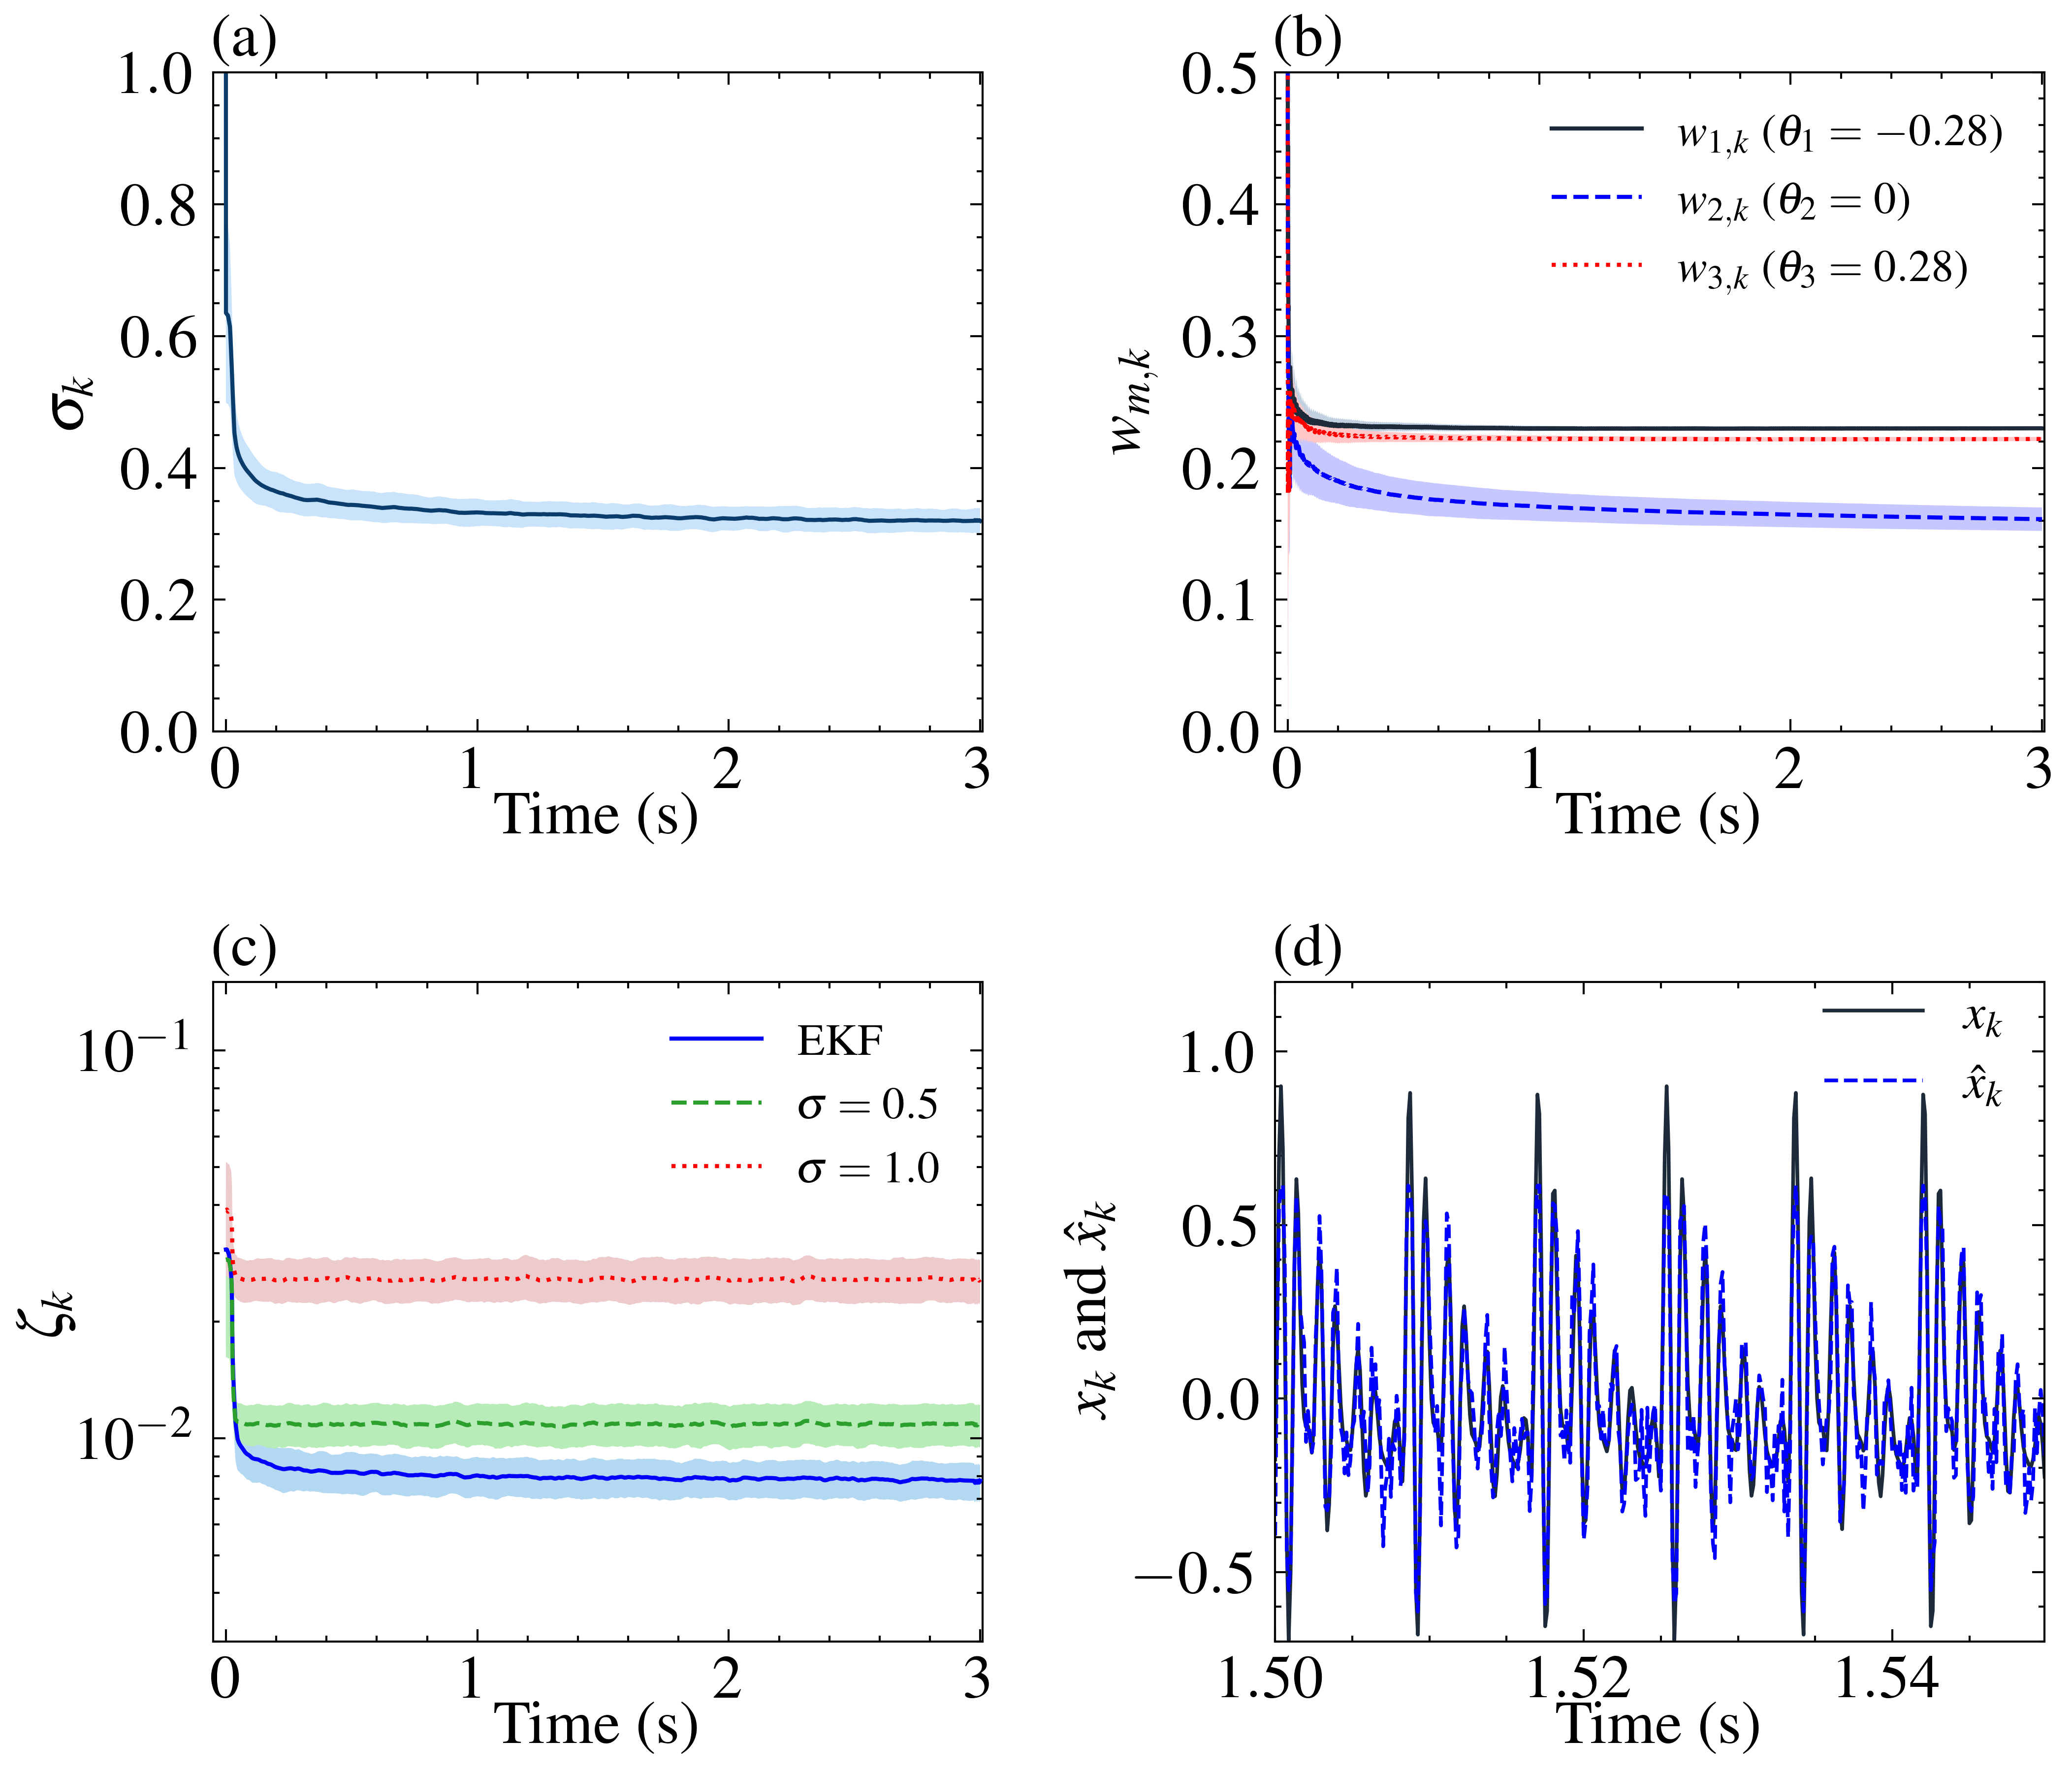

In [14]:
%matplotlib inline

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

import ssr_common as sc

# ============================================================
# Parameters (Jupyter Notebook)
# ============================================================
OUT_DIR = "D:/"
STEM = "Figspeech"
TRIALS = 100

ARR = sc.ArrayConfig(thetas=(-0.28, 0.0, 0.28), Ns=(15, 15, 15))
CFG = sc.AdaptConfig(
    R_w=0.1, P0_w=10.0, w0=1.0,
    Q_sigma=1e-3, R_sigma=1.0, P0_sigma=2.0,
    innovation="measured", jacobian_weights="updated",
    clip=0.3, bounds=(0.01, 5.0)
)
SIGMA0 = 1.0
FIXED = (0.5,1.0)
WINDOW = 100
SEED = 20261019

# ============================================================
# Synthesize speech signal & generate dither
# ============================================================
fs = 8000
t, x = sc.synth_vowel_a(fs=fs)
K = x.size
sx = float(np.std(x))
kurt = float(np.mean((x - x.mean()) ** 4) / sx ** 4 - 3.0)
print(f"speech: {K} samples, sigma_x = {sx:.4f}, excess kurtosis = {kurt:.2f}")

# independent dither streams, one per trial, shared by the adaptive and fixed-scale runs
ss = np.random.SeedSequence([SEED, 3])
# float32 keeps memory moderate (trials x 24000 x 45 values)
xi = np.stack([
    np.random.default_rng(c).standard_normal((K, ARR.N), dtype=np.float32)
    for c in ss.spawn(TRIALS)
])
xs = np.broadcast_to(x, (TRIALS, K))

# ============================================================
# Run adaptive & fixed-scale simulations
# ============================================================
ekf = sc.run_adaptive(xs, xi, ARR, CFG, SIGMA0)
cfg_fixed = sc.replace(CFG, scale_rule="fixed")
fixed = {sf: sc.run_adaptive(xs, xi, ARR, cfg_fixed, None, sigma_fixed=sf) for sf in FIXED}

if ekf["failed"].any():
    print(f"warning: {ekf['failed'].sum()} failed runs")

half = K // 2
p_half = float(np.mean(x[half:] ** 2))
ma_ekf = sc.moving_average(ekf["err2"], WINDOW, partial=True)
ma_fix = {sf: sc.moving_average(fixed[sf]["err2"], WINDOW, partial=True) for sf in FIXED}

mse_ekf = float(ma_ekf[:, half:].mean())
snr_ekf = 10 * np.log10(p_half / mse_ekf)
print(f"proposed : steady sigma = {ekf['sigma_traj'][:, half:].mean():.3f}, "
      f"MSE = {mse_ekf:.4f}, SNR = {snr_ekf:.2f} dB")

for sf in FIXED:
    mse = float(ma_fix[sf][:, half:].mean())
    snr = 10 * np.log10(p_half / mse)
    print(f"fixed {sf:<4}: MSE = {mse:.4f}, SNR = {snr:.2f} dB, gain of proposed = {snr_ekf - snr:.2f} dB")

w_ss = ekf["w_traj"][:, half:, :].mean(axis=(0, 1))
print("steady weights: " + ", ".join(f"w{m + 1} = {v:.3f}" for m, v in enumerate(w_ss)))

# ============================================================
# Plot figure
# ============================================================
sc.set_plot_style()
sm = int(0.05 * fs)                 # 0.05 s display smoothing
fig, axes = plt.subplots(2, 2, figsize=(8, 6.9))
plt.subplots_adjust(hspace=0.38, wspace=0.38)
ax_a, ax_b, ax_c, ax_d = axes.flatten()

# (a) sigma_k
m = uniform_filter1d(ekf["sigma_traj"].mean(0), sm)
sd = uniform_filter1d(ekf["sigma_traj"].std(0), sm)
m[0], sd[0] = SIGMA0, 0.0
ax_a.fill_between(t, np.maximum(m - sd, 0), m + sd, color=sc.lighten("#0a3d6b", 0.15), edgecolor="none")
ax_a.plot(t, m, color="#0a3d6b", lw=1.0)
ax_a.set(xlim=(-0.05, 3.01), ylim=(0, 1.0), yticks=np.arange(0, 1.01, 0.2))
ax_a.set_xlabel("Time (s)", labelpad=-2)
ax_a.set_ylabel(r"$\sigma_k$", labelpad=6)

# (b) group weights (unsmoothed); y-range as in the letter (initial w_0 = 1 is off-scale)
cols = ["#1c2a39", "b", "r"]
lss = ["-", "--", ":"]
for mi in range(ARR.M):
    wm, wsd = ekf["w_traj"][..., mi].mean(0), ekf["w_traj"][..., mi].std(0)
    ax_b.fill_between(t, np.maximum(wm - wsd, 0), wm + wsd, color=sc.lighten(cols[mi], 0.22),
                      edgecolor="none")
    ax_b.plot(t, wm, color=cols[mi], lw=1.0, ls=lss[mi],
              label=rf"$w_{{{mi+1},k}}$ ($\theta_{mi + 1}={ARR.thetas[mi]:g}$)")
ax_b.set(xlim=(-0.05, 3.01), ylim=(0.0, 0.5))
ax_b.set_xlabel("Time (s)", labelpad=-2)
ax_b.set_ylabel(r"$w_{m,k}$", labelpad=6)
ax_b.legend(loc="upper right", fontsize=11, framealpha=1.0)

# (c) 100-sample moving-average MSE (display-smoothed over 0.05 s)
curves = [
    ("EKF", ma_ekf, "b", "-", "#1f77b4"),
    (rf"$\sigma={FIXED[0]}$", ma_fix[FIXED[0]], "#2ca02c", "--", "#2ca02c"),
    (rf"$\sigma={FIXED[1]}$", ma_fix[FIXED[1]], "r", ":", "#c44e52")
]
for lab, ma, col, ls, shade in curves:
    mm = uniform_filter1d(ma.mean(0), sm)
    ssd = uniform_filter1d(ma.std(0), sm)
    ax_c.fill_between(t, np.maximum(mm - ssd, 1e-5), mm + ssd, color=sc.lighten(shade, 0.3),
                      edgecolor="none")
    ax_c.plot(t, mm, color=col, lw=1.0, ls=ls, zorder=5, label=lab)
ax_c.set_yscale("log")
ax_c.set(xlim=(-0.05, 3.01), ylim=(3e-3, 1.5e-1))
ax_c.set_xlabel("Time (s)", labelpad=-2)
ax_c.set_ylabel(r"$\zeta_k$", labelpad=1)
ax_c.legend(loc="upper right", fontsize=11)

# (d) 50 ms of the waveform, trial 1
k0, k1 = half, half + int(0.05 * fs)
ax_d.plot(t[k0:k1], x[k0:k1], color="#1c2a39", lw=0.9, label=r"$x_k$")
ax_d.plot(t[k0:k1], ekf["xhat"][0, k0:k1], color="blue", lw=0.9, ls="--", label=r"$\hat{x}_k$")
ax_d.set(xlim=(t[k0], t[k1 - 1]), ylim=(-0.7, 1.2))
ax_d.set_xlabel("Time (s)", labelpad=-2)
ax_d.set_ylabel(r"$x_k$ and $\hat{x}_k$", labelpad=4)
ax_d.legend(
    loc="upper right",
    bbox_to_anchor=(1.0, 1.05),
    fontsize=12,
    framealpha=1.0
)

for ax, lab in zip((ax_a, ax_b, ax_c, ax_d), "abcd"):
    ax.set_title(f"({lab})", loc="left", fontsize=15, pad=4)

# ============================================================
# Save and show figure
# ============================================================
sc.save_figure(fig, STEM, OUT_DIR)
print(f"saved {STEM}.eps/.pdf/.png in {OUT_DIR}")

plt.show()

speech: 24000 samples, sigma_x = 0.2822, excess kurtosis = 1.46
proposed (sigma0=0.5): steady sigma = 0.286, MSE = 0.0073, SNR = 10.36 dB | weights: w1 = 0.236, w2 = 0.137, w3 = 0.229
proposed (sigma0=1.0): steady sigma = 0.322, MSE = 0.0078, SNR = 10.07 dB | weights: w1 = 0.230, w2 = 0.163, w3 = 0.222
fixed 0.5 : MSE = 0.0109, SNR = 8.65 dB, gain vs proposed (0.1) = 1.71 dB
fixed 1.0 : MSE = 0.0257, SNR = 4.92 dB, gain vs proposed (0.1) = 5.44 dB
saved Figspeech.eps/.pdf/.png in D:/


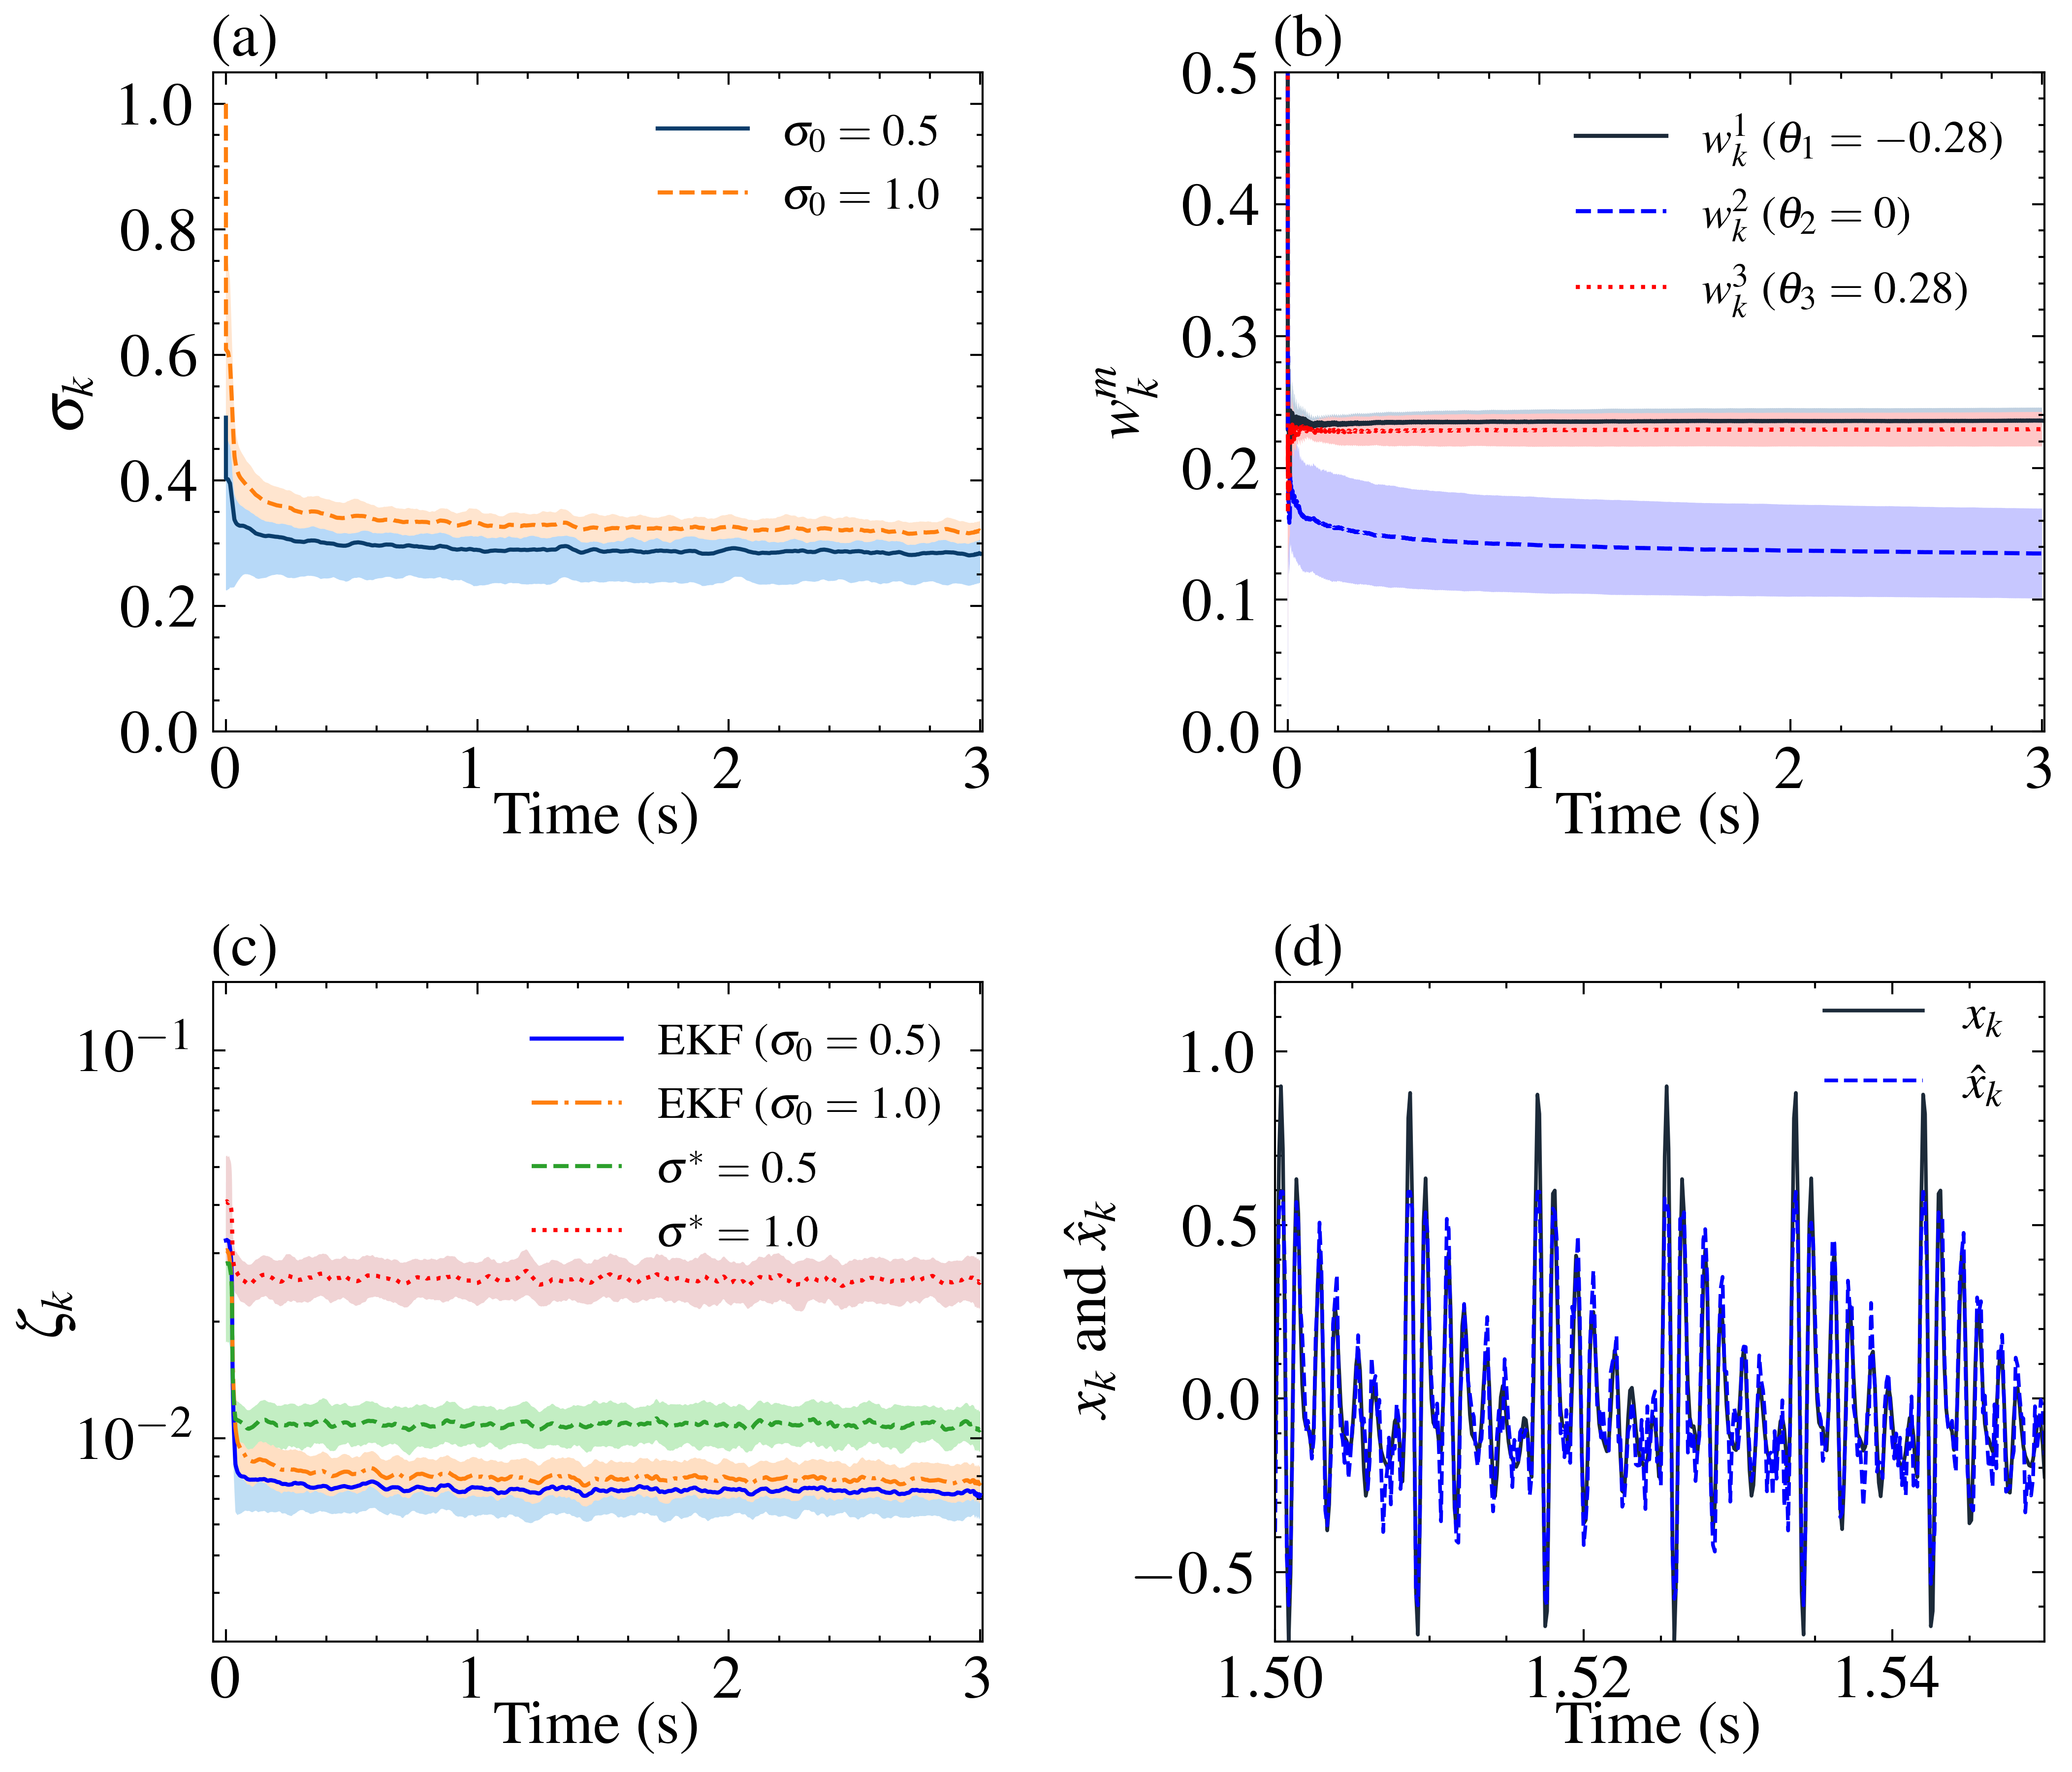

In [12]:
%matplotlib inline

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

import ssr_common as sc

# ============================================================
# Parameters (Jupyter Notebook)
# ============================================================
OUT_DIR = "D:/"
STEM = "Figspeech"
TRIALS = 20

ARR = sc.ArrayConfig(thetas=(-0.28, 0.0, 0.28), Ns=(15, 15, 15))
CFG = sc.AdaptConfig(
    R_w=0.1, P0_w=10.0, w0=1.0,
    Q_sigma=1e-3, R_sigma=1.0, P0_sigma=2.0,
    innovation="measured", jacobian_weights="updated",
    clip=0.3, bounds=(0.01, 5.0)
)
SIGMA0_LIST = (0.5, 1.0)   # 两个初始值：0.1 和 1.0
SIGMA0_REP = 0.5           # 图(b)权系数和图(d)波形的代表初值（可改为 1.0）
FIXED = (0.5, 1.0)
WINDOW = 100
SEED = 20261019

# ============================================================
# Synthesize speech signal & generate dither
# ============================================================
fs = 8000
t, x = sc.synth_vowel_a(fs=fs)
K = x.size
sx = float(np.std(x))
kurt = float(np.mean((x - x.mean()) ** 4) / sx ** 4 - 3.0)
print(f"speech: {K} samples, sigma_x = {sx:.4f}, excess kurtosis = {kurt:.2f}")

# independent dither streams, one per trial, shared by the adaptive and fixed-scale runs
ss = np.random.SeedSequence([SEED, 3])
xi = np.stack([
    np.random.default_rng(c).standard_normal((K, ARR.N), dtype=np.float32)
    for c in ss.spawn(TRIALS)
])
xs = np.broadcast_to(x, (TRIALS, K))

# ============================================================
# Run adaptive (two initial values) & fixed-scale simulations
# ============================================================
ekf = {s0: sc.run_adaptive(xs, xi, ARR, CFG, s0) for s0 in SIGMA0_LIST}
cfg_fixed = sc.replace(CFG, scale_rule="fixed")
fixed = {sf: sc.run_adaptive(xs, xi, ARR, cfg_fixed, None, sigma_fixed=sf) for sf in FIXED}

for s0 in SIGMA0_LIST:
    if ekf[s0]["failed"].any():
        print(f"warning: {ekf[s0]['failed'].sum()} failed runs for sigma0 = {s0}")

half = K // 2
p_half = float(np.mean(x[half:] ** 2))
ma_ekf = {s0: sc.moving_average(ekf[s0]["err2"], WINDOW, partial=True) for s0 in SIGMA0_LIST}
ma_fix = {sf: sc.moving_average(fixed[sf]["err2"], WINDOW, partial=True) for sf in FIXED}

snr_ekf = {}
for s0 in SIGMA0_LIST:
    mse_val = float(ma_ekf[s0][:, half:].mean())
    snr_val = 10 * np.log10(p_half / mse_val)
    snr_ekf[s0] = snr_val
    w_ss = ekf[s0]["w_traj"][:, half:, :].mean(axis=(0, 1))
    w_str = ", ".join(f"w{m + 1} = {v:.3f}" for m, v in enumerate(w_ss))
    print(f"proposed (sigma0={s0:<3}): steady sigma = {ekf[s0]['sigma_traj'][:, half:].mean():.3f}, "
          f"MSE = {mse_val:.4f}, SNR = {snr_val:.2f} dB | weights: {w_str}")

for sf in FIXED:
    mse = float(ma_fix[sf][:, half:].mean())
    snr = 10 * np.log10(p_half / mse)
    print(f"fixed {sf:<4}: MSE = {mse:.4f}, SNR = {snr:.2f} dB, "
          f"gain vs proposed (0.1) = {snr_ekf[0.5] - snr:.2f} dB")

# ============================================================
# Plot figure
# ============================================================
sc.set_plot_style()
sm = int(0.05 * fs)                 # 0.05 s display smoothing
fig, axes = plt.subplots(2, 2, figsize=(8, 6.9))
plt.subplots_adjust(hspace=0.38, wspace=0.38)
ax_a, ax_b, ax_c, ax_d = axes.flatten()

# (a) sigma_k for both initial values (0.1 and 1.0)
cols_a = ["#0a3d6b", "#ff7f0e"]
lss_a = ["-", "--"]
for i, s0 in enumerate(SIGMA0_LIST):
    m = uniform_filter1d(ekf[s0]["sigma_traj"].mean(0), sm)
    sd = uniform_filter1d(ekf[s0]["sigma_traj"].std(0), sm)
    m[0], sd[0] = s0, 0.0
    ax_a.fill_between(t, np.maximum(m - sd, 0), m + sd,
                      color=sc.lighten(cols_a[i], 0.2), edgecolor="none")
    ax_a.plot(t, m, color=cols_a[i], lw=1.0, ls=lss_a[i], label=rf"$\sigma_0={s0}$")

ax_a.set(xlim=(-0.05, 3.01), ylim=(0, 1.05), yticks=np.arange(0, 1.05, 0.2))
ax_a.set_xlabel("Time (s)", labelpad=-2)
ax_a.set_ylabel(r"$\sigma_k$", labelpad=6)
ax_a.legend(loc="upper right", fontsize=11)

# (b) group weights (representative: SIGMA0_REP)
ekf_rep = ekf[SIGMA0_REP]
cols_b = ["#1c2a39", "b", "r"]
lss_b = ["-", "--", ":"]
for mi in range(ARR.M):
    wm, wsd = ekf_rep["w_traj"][..., mi].mean(0), ekf_rep["w_traj"][..., mi].std(0)
    ax_b.fill_between(t, np.maximum(wm - wsd, 0), wm + wsd,
                      color=sc.lighten(cols_b[mi], 0.22), edgecolor="none")
    ax_b.plot(t, wm, color=cols_b[mi], lw=1.0, ls=lss_b[mi],
              label=rf"$w_k^{mi + 1}$ ($\theta_{mi + 1}={ARR.thetas[mi]:g}$)")

ax_b.set(xlim=(-0.05, 3.01), ylim=(0.0, 0.5))
ax_b.set_xlabel("Time (s)", labelpad=-2)
ax_b.set_ylabel(r"$w_k^m$", labelpad=6)
ax_b.legend(loc="upper right", fontsize=11, framealpha=1.0)

# (c) 100-sample moving-average MSE (both EKF initializations + fixed scales)
curves = [
    (rf"EKF ($\sigma_0={SIGMA0_LIST[0]}$)", ma_ekf[SIGMA0_LIST[0]], "b", "-", "#1f77b4"),
    (rf"EKF ($\sigma_0={SIGMA0_LIST[1]}$)", ma_ekf[SIGMA0_LIST[1]], "#ff7f0e", "-.", "#ff7f0e"),
    (rf"$\sigma^\ast={FIXED[0]}$", ma_fix[FIXED[0]], "#2ca02c", "--", "#2ca02c"),
    (rf"$\sigma^\ast={FIXED[1]}$", ma_fix[FIXED[1]], "r", ":", "#c44e52")
]
for lab, ma, col, ls, shade in curves:
    mm = uniform_filter1d(ma.mean(0), sm)
    ssd = uniform_filter1d(ma.std(0), sm)
    ax_c.fill_between(t, np.maximum(mm - ssd, 1e-5), mm + ssd,
                      color=sc.lighten(shade, 0.25), edgecolor="none")
    ax_c.plot(t, mm, color=col, lw=1.0, ls=ls, zorder=5, label=lab)

ax_c.set_yscale("log")
ax_c.set(xlim=(-0.05, 3.01), ylim=(3e-3, 1.5e-1))
ax_c.set_xlabel("Time (s)", labelpad=-2)
ax_c.set_ylabel(r"$\zeta_k$", labelpad=1)
ax_c.legend(loc="upper right", fontsize=11)

# (d) 50 ms of the waveform, trial 1 (representative: SIGMA0_REP)
k0, k1 = half, half + int(0.05 * fs)
ax_d.plot(t[k0:k1], x[k0:k1], color="#1c2a39", lw=0.9, label=r"$x_k$")
ax_d.plot(t[k0:k1], ekf_rep["xhat"][0, k0:k1], color="blue", lw=0.9, ls="--", label=r"$\hat{x}_k$")
ax_d.set(xlim=(t[k0], t[k1 - 1]), ylim=(-0.7, 1.2))
ax_d.set_xlabel("Time (s)", labelpad=-2)
ax_d.set_ylabel(r"$x_k$ and $\hat{x}_k$", labelpad=4)
ax_d.legend(
    loc="upper right",
    bbox_to_anchor=(1.0, 1.05),
    fontsize=12,
    framealpha=1.0
)
for ax, lab in zip((ax_a, ax_b, ax_c, ax_d), "abcd"):
    ax.set_title(f"({lab})", loc="left", fontsize=15, pad=4)

# ============================================================
# Save and show figure
# ============================================================
sc.save_figure(fig, STEM, OUT_DIR)
print(f"saved {STEM}.eps/.pdf/.png in {OUT_DIR}")

plt.show()